# **1. Identify Problem**

### **Tujuan:**

Mengelompokkan nasabah berdasarkan karakteristik dan perilaku untuk memahami segmentasi pelanggan secara lebih efektif.

### **Penjelasan:**

Customer segmentation digunakan untuk:

* memahami perilaku nasabah
* mengidentifikasi kelompok bernilai tinggi
* membantu strategi marketing & retention

# **2. Data Collection**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

Dataset diambil dari Kaggle yang berisi informasi demografi, finansial, serta perilaku nasabah asuransi.

In [ ]:
import kagglehub

# Download dataset dari Kaggle
path = kagglehub.dataset_download("ravalsmit/customer-segmentation-data")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'customer-segmentation-data' dataset.
Path to dataset files: /kaggle/input/customer-segmentation-data


In [ ]:
df = pd.read_csv('/kaggle/input/customer-segmentation-data/customer_segmentation_data.csv')
df.head()

,Customer ID,Age,Gender,Marital Status,Education Level,Geographic Information,Occupation,Income Level,Behavioral Data,Purchase History,Interactions with Customer Service,Insurance Products Owned,Coverage Amount,Premium Amount,Policy Type,Customer Preferences,Preferred Communication Channel,Preferred Contact Time,Preferred Language,Segmentation Group
0,84966,23,Female,Married,Associate Degree,Mizoram,Entrepreneur,70541,policy5,04-10-2018,Phone,policy2,366603,2749,Group,Email,In-Person Meeting,Afternoon,English,Segment5
1,95568,26,Male,Widowed,Doctorate,Goa,Manager,54168,policy5,11-06-2018,Chat,policy1,780236,1966,Group,Mail,In-Person Meeting,Morning,French,Segment5
2,10544,29,Female,Single,Associate Degree,Rajasthan,Entrepreneur,73899,policy5,06-05-2021,Email,policy3,773926,4413,Group,Email,Mail,Evening,German,Segment3
3,77033,20,Male,Divorced,Bachelor's Degree,Sikkim,Entrepreneur,63381,policy5,09-02-2018,Chat,policy2,787815,4342,Family,Text,In-Person Meeting,Anytime,French,Segment3
4,88160,25,Female,Separated,Bachelor's Degree,West Bengal,Manager,38794,policy1,09-10-2018,Chat,policy4,366506,1276,Family,Email,Text,Weekends,English,Segment2


# **3. Prepare Data**

### **3.1 Data Cleaning**
Data dibersihkan dari duplikasi dan dicek missing value untuk memastikan kualitas data.

In [ ]:
# drop duplicate
df = df.drop_duplicates()

In [ ]:
# cek missing
print(df.isnull().sum())

Customer ID                           0
Age                                   0
Gender                                0
Marital Status                        0
Education Level                       0
Geographic Information                0
Occupation                            0
Income Level                          0
Behavioral Data                       0
Purchase History                      0
Interactions with Customer Service    0
Insurance Products Owned              0
Coverage Amount                       0
Premium Amount                        0
Policy Type                           0
Customer Preferences                  0
Preferred Communication Channel       0
Preferred Contact Time                0
Preferred Language                    0
Segmentation Group                    0
dtype: int64


In [ ]:
df.tail()

,Customer ID,Age,Gender,Marital Status,Education Level,Geographic Information,Occupation,Income Level,Behavioral Data,Purchase History,Interactions with Customer Service,Insurance Products Owned,Coverage Amount,Premium Amount,Policy Type,Customer Preferences,Preferred Communication Channel,Preferred Contact Time,Preferred Language,Segmentation Group
53498,44809,35,Female,Divorced,Associate Degree,Andaman and Nicobar Islands,Salesperson,120850,policy3,01-01-2019,Mobile App,policy1,586401,4404,Family,In-Person Meeting,Phone,Afternoon,German,Segment5
53499,65485,61,Male,Single,Doctorate,Himachal Pradesh,Entrepreneur,122309,policy5,5/18/2021,Mobile App,policy4,637733,1285,Group,Text,Mail,Afternoon,German,Segment1
53500,26213,25,Male,Divorced,Doctorate,Assam,Teacher,49258,policy2,11/27/2018,In-Person,policy1,631057,4407,Individual,Text,Text,Weekends,French,Segment4
53501,63136,42,Male,Married,Doctorate,Andhra Pradesh,Artist,66301,policy4,06-04-2021,In-Person,policy1,730385,4482,Business,Mail,Phone,Morning,French,Segment5
53502,62125,20,Male,Divorced,Doctorate,Daman and Diu,Salesperson,136632,policy2,10/14/2022,Phone,policy1,743262,4499,Group,Text,In-Person Meeting,Evening,German,Segment2


### **3.2 Feature Engineering**

**a. Marital Status Encoding**

Status pernikahan diubah menjadi variabel biner karena mempengaruhi perilaku finansial dan tingkat risiko.

In [ ]:
print(df['Marital Status'].unique())

['Married' 'Widowed' 'Single' 'Divorced' 'Separated']


In [ ]:
df['Marital_Married'] = (df['Marital Status'] == 'Married').astype(int)
df['Marital_Widowed'] = (df['Marital Status'] == 'Widowed').astype(int)
df['Marital_Divorced'] = (df['Marital Status'] == 'Divorced').astype(int)
df['Marital_Separated'] = (df['Marital Status'] == 'Separated').astype(int)

In [ ]:
df[['Marital_Married', 'Marital_Widowed', 'Marital_Divorced', 'Marital_Separated']].head()

,Marital_Married,Marital_Widowed,Marital_Divorced,Marital_Separated
0,1,0,0,0
1,0,1,0,0
2,0,0,0,0
3,0,0,1,0
4,0,0,0,1


**b. Income Stability**

Pekerjaan dikelompokkan berdasarkan stabilitas pendapatan untuk merepresentasikan kondisi ekonomi nasabah.

In [ ]:
print(df['Occupation'].unique())

['Entrepreneur' 'Manager' 'Nurse' 'Artist' 'Salesperson' 'Lawyer'
 'Teacher' 'Doctor' 'Engineer']


In [ ]:
def map_income_stability(job):
    if job in ['Doctor', 'Lawyer', 'Engineer', 'Nurse', 'Teacher']:
        return 3   # High
    elif job in ['Entrepreneur', 'Artist', 'Salesperson']:
        return 1   # Variable
    elif job == 'Manager':
        return 2   # Medium
    else:
        return 0   # Other (opsional)

In [ ]:
df['Income_Stability_Score'] = df['Occupation'].apply(map_income_stability)

In [ ]:
print(df[['Occupation', 'Income_Stability_Score']].head(10))

     Occupation  Income_Stability_Score
0  Entrepreneur                       1
1       Manager                       2
2  Entrepreneur                       1
3  Entrepreneur                       1
4       Manager                       2
5         Nurse                       3
6       Manager                       2
7        Artist                       1
8   Salesperson                       1
9        Artist                       1


**c. Behavioral Rank**

Mengubah data perilaku menjadi nilai numerik untuk menangkap tingkat ketertarikan terhadap produk.

In [ ]:
df['Behavioral_Rank'] = df['Behavioral Data'].str.extract('(\d+)').astype(int)

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_13674/1859587810.py:1: SyntaxWarning: invalid escape sequence '\d'
  df['Behavioral_Rank'] = df['Behavioral Data'].str.extract('(\d+)').astype(int)


**d. Tenure (dari tanggal)**

Mengukur lamanya nasabah sejak transaksi terakhir sebagai indikator aktivitas.

In [ ]:
df['Purchase History'] = pd.to_datetime(
    df['Purchase History'],
    format='mixed',
    dayfirst=True
)

In [ ]:
# Gunakan tanggal transaksi paling baru di data sebagai referensi
ref_date = df['Purchase History'].max()
df['Tenure_Days'] = (ref_date - df['Purchase History']).dt.days

**e. Interaction Score**

Mengubah jenis interaksi menjadi skor numerik sebagai indikator engagement.

In [ ]:
print(df['Interactions with Customer Service'].unique())

['Phone' 'Chat' 'Email' 'Mobile App' 'In-Person']


In [ ]:
interaction_map = {
    'Email': 1,
    'Mobile App': 2,
    'Chat': 3,
    'Phone': 4,
    'In-Person': 5
}

df['Interaction_Score'] = df['Interactions with Customer Service'].map(interaction_map)

**f. Product_Rank (Insurance Products Owned)**

Kolom Insurance Products Owned diubah menjadi nilai numerik (Product_Rank) untuk merepresentasikan tingkat produk yang dimiliki oleh nasabah.

In [ ]:
df['Product_Rank'] = df['Insurance Products Owned'].str.extract('(\d+)').astype(int)

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_13674/3558213036.py:1: SyntaxWarning: invalid escape sequence '\d'
  df['Product_Rank'] = df['Insurance Products Owned'].str.extract('(\d+)').astype(int)


**g. Monetary**

Menggabungkan premium dan coverage sebagai representasi nilai finansial nasabah.

In [ ]:
df['Monetary'] = df['Premium Amount'] + df['Coverage Amount']

**h. Interest Gap**

Selisih antara minat dan produk yang dimiliki untuk mengidentifikasi peluang upselling.

In [ ]:
df['Interest_Gap'] = df['Behavioral_Rank'] - df['Product_Rank']

**i. Protection Breadth**

Mengukur luas cakupan proteksi nasabah sebagai indikator tanggung jawab finansial dan loyalitas.

In [ ]:
print(df['Policy Type'].unique())

['Group' 'Family' 'Individual' 'Business']


In [ ]:
policy_map = {
    'Individual': 1,
    'Group': 2,
    'Family': 3,
    'Business': 4
}

df['Protection_Breadth'] = df['Policy Type'].map(policy_map)

In [ ]:
print(df[['Policy Type', 'Protection_Breadth']].tail())

      Policy Type  Protection_Breadth
53498      Family                   3
53499       Group                   2
53500  Individual                   1
53501    Business                   4
53502       Group                   2


# **4. Feature Selection**

Dipilih fitur yang paling relevan untuk menggambarkan profil, perilaku, dan nilai nasabah.

In [ ]:
print(df.dtypes)

Customer ID                                    int64
Age                                            int64
Gender                                        object
Marital Status                                object
Education Level                               object
Geographic Information                        object
Occupation                                    object
Income Level                                   int64
Behavioral Data                               object
Purchase History                      datetime64[ns]
Interactions with Customer Service            object
Insurance Products Owned                      object
Coverage Amount                                int64
Premium Amount                                 int64
Policy Type                                   object
Customer Preferences                          object
Preferred Communication Channel               object
Preferred Contact Time                        object
Preferred Language                            

In [ ]:
selected_cols = [
    'Age',
    'Income Level',
    'Monetary',
    'Tenure_Days',
    'Interest_Gap',
    'Interaction_Score',
    'Marital_Married',
    'Marital_Widowed',
    'Marital_Divorced',
    'Marital_Separated',
    'Income_Stability_Score',
    'Protection_Breadth'
]

df_model = df[selected_cols].copy()

# **5. Exploratory Data Analysis**

**Heatmap**

Digunakan untuk melihat hubungan antar fitur dan mendeteksi redundansi.

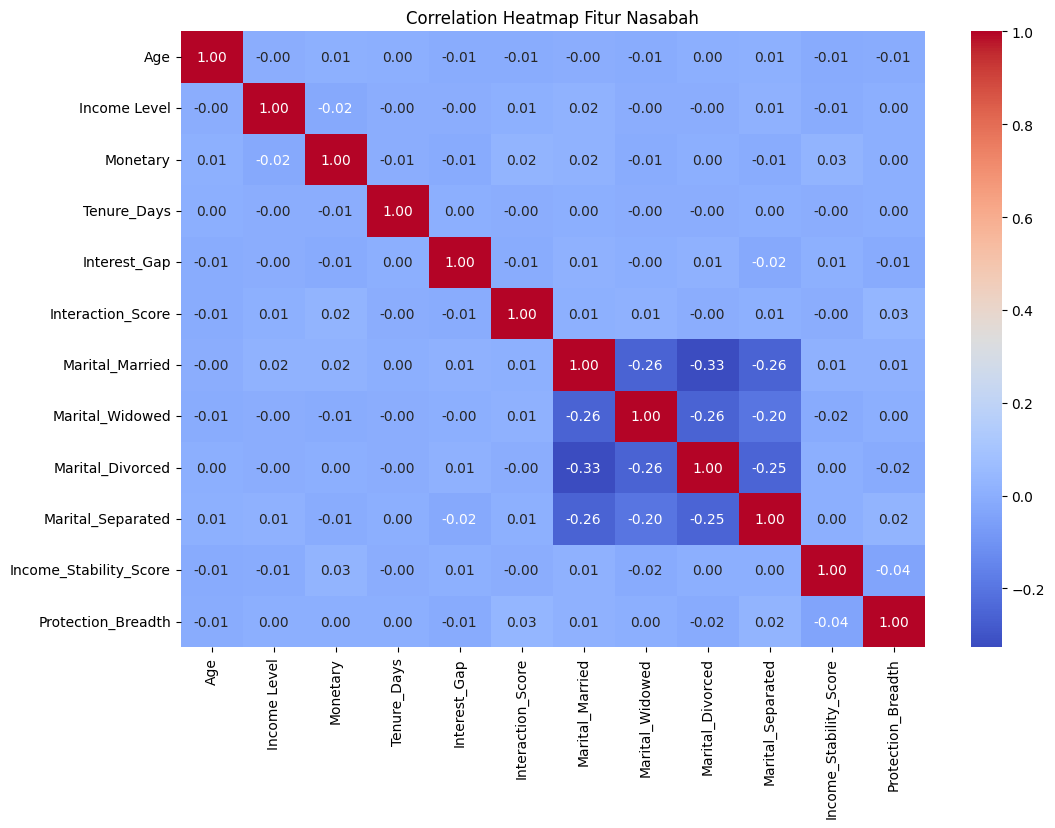

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Menghitung korelasi antar fitur
corr_matrix = df[selected_cols].corr()

# Menampilkan Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap Fitur Nasabah')
plt.show()

**PCA Visualization**

PCA digunakan untuk mereduksi dimensi dan memvisualisasikan distribusi data sebelum clustering.

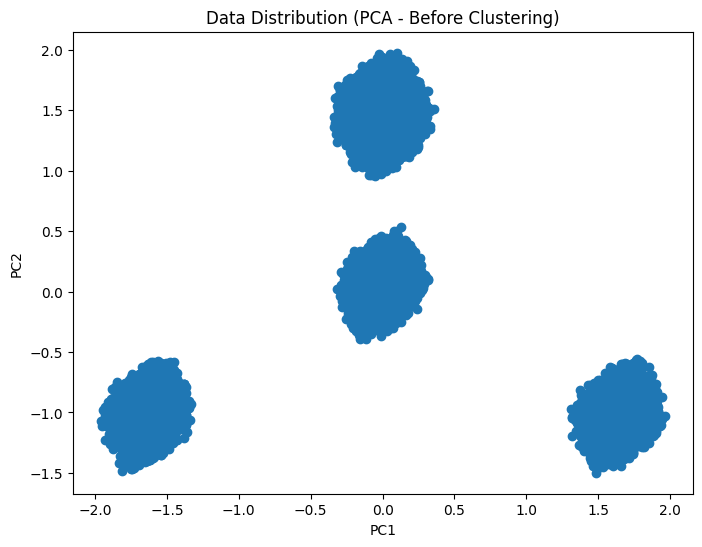

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1])
plt.title('Data Distribution (PCA - Before Clustering)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

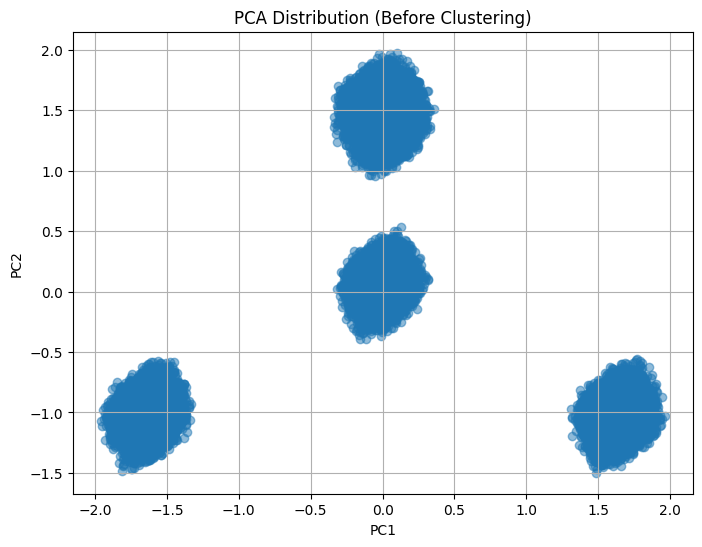

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], alpha=0.5)
plt.title('PCA Distribution (Before Clustering)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.grid(True)
plt.show()

In [ ]:
print(df_model.head())
print(df_model.isnull().sum())

   Age  Income Level  Monetary  Tenure_Days  Interest_Gap  Interaction_Score  \
0   23         70541    369352         1911             3                  4   
1   26         54168    782202         2026             4                  3   
2   29         73899    778339          966             2                  1   
3   20         63381    792157         2148             3                  3   
4   25         38794    367782         1906            -3                  3   

   Marital_Married  Marital_Widowed  Marital_Divorced  Marital_Separated  \
0                1                0                 0                  0   
1                0                1                 0                  0   
2                0                0                 0                  0   
3                0                0                 1                  0   
4                0                0                 0                  1   

   Income_Stability_Score  Protection_Breadth  
0             

# **6. Data Preprocessing**

**Train-Test Split**

Digunakan untuk menguji stabilitas model meskipun clustering bersifat unsupervised.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df_model.copy()

X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)

**Scaling**

StandardScaler digunakan agar semua fitur memiliki skala yang sama.

In [ ]:
# scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**PCA**

Mengurangi dimensi data untuk mengurangi noise dan meningkatkan performa clustering.

In [ ]:
# PCA
pca = PCA(n_components=3)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# **7. Model Building (HDBSCAN)**

HDBSCAN digunakan karena mampu mendeteksi cluster dengan bentuk kompleks dan menangani noise.

**Parameter Tuning**

Dilakukan eksplorasi parameter untuk mendapatkan kombinasi terbaik berdasarkan silhouette score.

In [ ]:
import hdbscan
from sklearn.metrics import silhouette_score

best_score = -1
best_params = None

results = []

for min_cluster_size in range(50, 101, 5):
    for min_samples in range(20, 50, 5):

        clusterer = hdbscan.HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=min_samples
        )

        labels = clusterer.fit_predict(X_train_pca)

        # buang noise
        mask = labels != -1

        if len(set(labels[mask])) > 1:
            score = silhouette_score(X_train_pca[mask], labels[mask])

            results.append({
                'min_cluster_size': min_cluster_size,
                'min_samples': min_samples,
                'score': score
            })

            if score > best_score:
                best_score = score
                best_params = (min_cluster_size, min_samples)

print("Best Score:", best_score)
print("Best Params:", best_params)

Best Score: 0.8644317725325575
Best Params: (50, 20)


In [ ]:
best_clusterer = hdbscan.HDBSCAN(
    min_cluster_size=best_params[0],
    min_samples=best_params[1],
    prediction_data=True   # 🔥 WAJIB
)

train_labels = best_clusterer.fit_predict(X_train_pca)

In [ ]:
test_labels, _ = hdbscan.approximate_predict(best_clusterer, X_test_pca)

# **8. Evaluation**

Silhouette score digunakan untuk mengukur kualitas cluster.

In [ ]:
mask_train = train_labels != -1

if len(set(train_labels[mask_train])) > 1:
    train_score = silhouette_score(X_train_pca[mask_train], train_labels[mask_train])
    print("Train Silhouette:", train_score)

Train Silhouette: 0.8644317725325575


In [ ]:
X_train['Cluster'] = train_labels

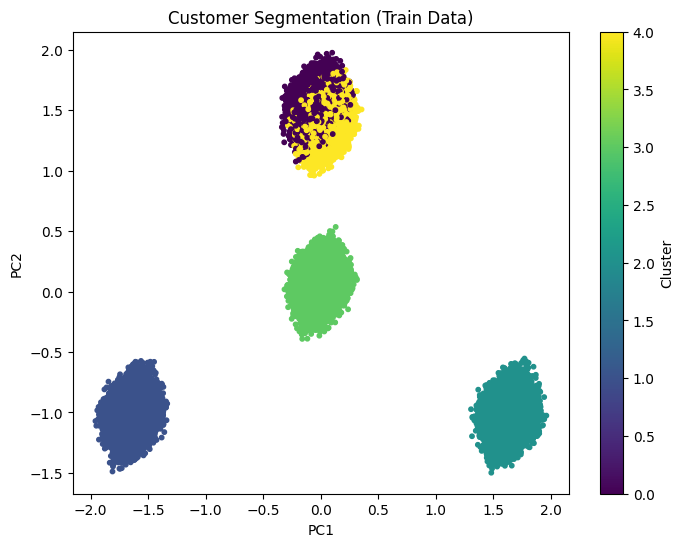

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=train_labels,
    cmap='viridis',
    s=10
)

plt.title('Customer Segmentation (Train Data)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(label='Cluster')
plt.show()

In [ ]:
mask_test = test_labels != -1

if len(set(test_labels[mask_test])) > 1:
    test_score = silhouette_score(X_test_pca[mask_test], test_labels[mask_test])
    print("Test Silhouette:", test_score)

Test Silhouette: 0.8647642155551721


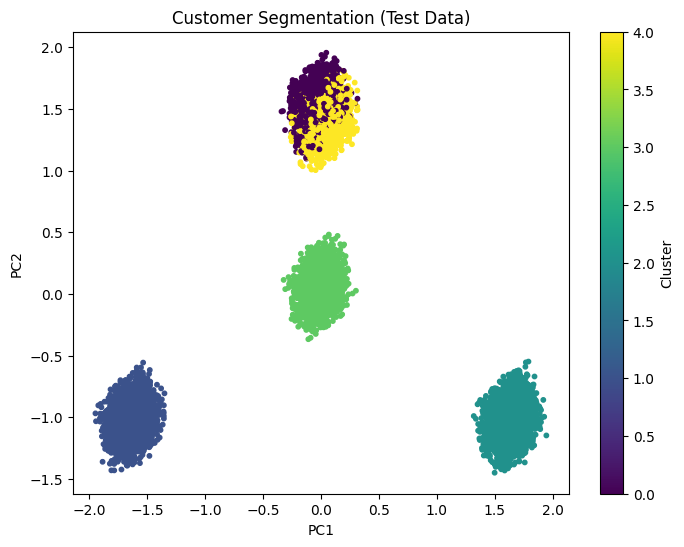

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(
    X_test_pca[:, 0],
    X_test_pca[:, 1],
    c=test_labels,
    cmap='viridis',
    s=10
)

plt.title('Customer Segmentation (Test Data)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(label='Cluster')
plt.show()

SC = 0,86

Menunjukkan bahwa cluster memiliki pemisahan yang sangat baik dengan overlap yang minimal.

In [ ]:
import numpy as np

print("Jumlah cluster:", len(set(train_labels)) - (1 if -1 in train_labels else 0))
print("Jumlah noise:", np.sum(train_labels == -1))

Jumlah cluster: 5
Jumlah noise: 0


**Clustering vs Label Asli**

In [ ]:
df_compare = X_train.copy()
df_compare['Cluster'] = train_labels
df_compare['True_Label'] = df.loc[X_train.index, 'Segmentation Group']

pd.crosstab(df_compare['Cluster'], df_compare['True_Label'])

True_Label,Segment1,Segment2,Segment3,Segment4,Segment5
Cluster,,,,,
0,1179,1566,1304,1377,1871
1,1687,2207,1644,1976,3002
2,1676,2296,1679,1939,2957
3,1139,1501,1484,1413,1818
4,1243,1596,1314,1381,1553


Hasil perbandingan menunjukkan bahwa cluster yang dihasilkan tidak sepenuhnya selaras dengan segmentasi yang telah ada, yang mengindikasikan bahwa model menemukan pola alternatif berdasarkan karakteristik data.

# **9. Communicate Result**

In [ ]:
cluster_summary = X_train.groupby('Cluster').mean()
cluster_summary = cluster_summary.sort_index()
print(cluster_summary)

               Age  Income Level       Monetary  Tenure_Days  Interest_Gap  \
Cluster                                                                      
0        43.902426  82697.183363  490239.609977  1083.878169      0.080170   
1        44.191137  82561.050875  496539.773678  1083.232313      0.121624   
2        44.132170  84059.187541  502209.051673  1087.067128      0.106002   
3        44.198504  79858.047859  492699.108770  1088.494494      0.038205   
4        44.396077  84306.906307  488608.855228  1088.078171     -0.004374   

         Interaction_Score  Marital_Married  Marital_Widowed  \
Cluster                                                        
0                 2.987118              0.0              1.0   
1                 2.955687              0.0              0.0   
2                 2.981132              1.0              0.0   
3                 2.895309              0.0              0.0   
4                 2.982785              0.0              0.0   

    

### **Cluster 0 - Passive Loyal (Widowed Segment)**

**Karakteristik:**

Age: 43.90

Income: 82,697

Monetary: 490,239

Tenure: 1083 hari

Interest Gap: 0.08 (rendah)

Interaction Score: 2.99

Marital: Widowed = 1.0 (dominan)

Income Stability: 2.10

Protection Breadth: 2.60

**Interpretasi:**
Cluster ini didominasi oleh nasabah widowed dengan tingkat proteksi cukup luas (2.60) dan nilai finansial yang stabil.
Meskipun cukup aktif (interaction ~3), mereka memiliki Interest Gap rendah, artinya tidak terlalu tertarik untuk upgrade produk

**Insight:**
Nasabah loyal tetapi pasif dalam eksplorasi produk baru.

**Strategi:**
Edukasi produk (bukan hard selling)
dan fokus pada keamanan & trust

### **Cluster 1 - Upselling Opportunity (Divorced Segment)**

**Karakteristik:**

Age: 44.19

Income: 82,561

Monetary: 496,539

Tenure: 1083 hari

Interest Gap: 0.12 (tertinggi)

Interaction Score: 2.96

Marital: Divorced = 1.0

Income Stability: 2.13

Protection Breadth: 2.56


**Interpretasi:**
Cluster ini punya Interest Gap paling tinggi (0.12), artinya mereka tertarik produk yang lebih tinggi dari yang dimiliki. Nilai monetary juga cukup tinggi (~496k), jadi mereka punya kapasitas finansial.

**Insight:**
Target terbaik untuk upselling

**Strategi:**
Cross-selling & upselling
Promo upgrade produk
Penawaran personal

### **Cluster 2 - High Value VIP (Family-Oriented)**

**Karakteristik:**
Age: 44.13
Income: 84,059
Monetary: 502,209 (tertinggi)
Tenure: 1087 hari
Interest Gap: 0.106
Interaction Score: 2.98
Marital: Married = 1.0
Income Stability: 2.16 (tertinggi)
Protection Breadth: 2.62

**Interpretasi:**
Ini adalah cluster terbaik:

Monetary tertinggi → high value customer

Income tinggi → daya beli kuat

Married → tanggungan keluarga

Protection luas → loyal

**Insight:**
Nasabah premium dengan loyalitas tinggi

**Strategi:**
Loyalty program, prioritas layanan, retention strategy

### **Cluster 3 - Low Engagement Segment**

**Karakteristik:**

Age: 44.19

Income: 79,858 (terendah)

Monetary: 492,699

Tenure: 1088 hari

Interest Gap: 0.038 (rendah)

Interaction Score: 2.89 (terendah)

Marital: mayoritas single/divorced

Income Stability: 2.13

Protection Breadth: 2.53 (terendah)


**Interpretasi:**
Cluster ini punya interaction paling rendah, protection paling kecil, interest rendah, artinya kurang engaged dan tidak terlalu tertarik produk

**Insight:**
Berpotensi menjadi churn customer

**Strategi:**
Campaign engagement, reminder / follow-up, dan penawaran ringan

### **Cluster 4 - Stable Customer (Satisfied Segment)**

**Karakteristik:**

Age: 44.40 (tertinggi)

Income: 84,306 (tertinggi)

Monetary: 488,608

Tenure: 1088 hari

Interest Gap: -0.004 (negatif)

Interaction Score: 2.98

Marital: Separated = 1.0

Income Stability: 2.14

Protection Breadth: 2.64 (tertinggi)

**Interpretasi:**
Interest Gap negatif, artinya
mereka tidak tertarik upgrade bahkan mungkin over-covered. Protection paling tinggi, artinya sudah lengkap

**Insight:**
Customer stabil dan puas dengan produk saat ini

**Strategi:**
Maintain relationship, jangan terlalu agresif jualan, dan fokus retention

Hasil clustering menunjukkan bahwa pelanggan dapat dibagi menjadi lima segmen utama, termasuk pelanggan bernilai tinggi, pelanggan potensial untuk upselling, serta pelanggan dengan tingkat engagement rendah yang berpotensi churn.